# Processamento de Imagens — Aula 5

**Tema:** suavização, limiarização (Otsu e adaptativa) e detecção de contornos com OpenCV.

Notebook reconstruído do PDF *proc img 2345 - Colab.PDF*, preservando a sequência dos exemplos e gerando novamente as saídas gráficas.

**Ressalva de reconstrução:** no PDF, o final da chamada `cv2.adaptiveThreshold(...)` aparece cortado. Os parâmetros `cv2.THRESH_BINARY, 101, -10` foram determinados por testes para reproduzir visualmente o exemplo e obter os mesmos 24 contornos mostrados. Não é possível confirmar que eram exatamente os parâmetros escritos no Colab original.

## Bibliotecas e função de visualização

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data


def mostrar(imagens, titulos, cmap='gray', tamanho=4):
    n = len(imagens)
    plt.figure(figsize=(tamanho * n, tamanho))
    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(imagens[i], cmap=cmap)
        plt.title(titulos[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()


## Imagens de exemplo

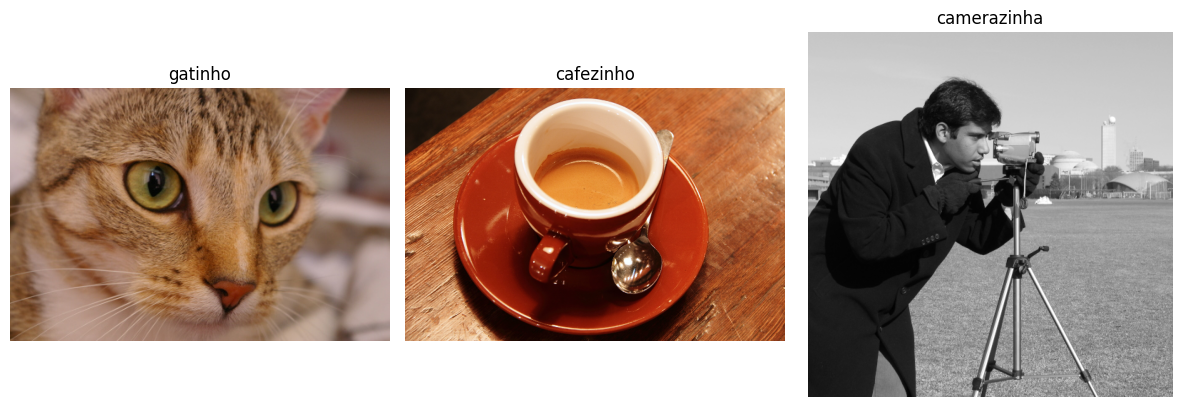

In [2]:
gato = data.cat()
cafe = data.coffee()
camera = data.camera()

mostrar([gato, cafe, camera], ["gatinho", "cafezinho", "camerazinha"])


## Suavização gaussiana

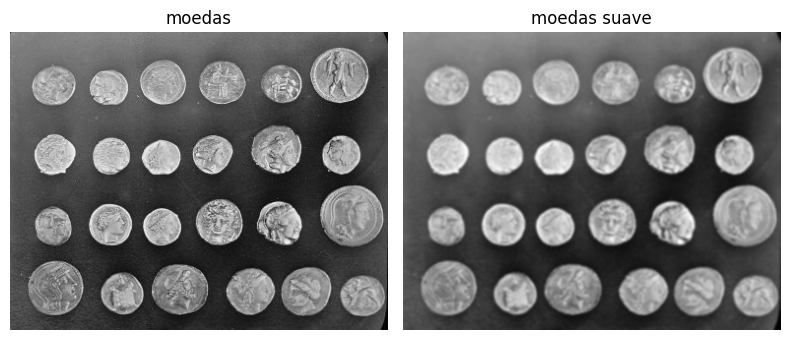

In [3]:
moedas = data.coins()
moedas_suave = cv2.GaussianBlur(moedas, (5, 5), 0)

mostrar([moedas, moedas_suave], ["moedas", "moedas suave"])


## Limiarização de Otsu e limiarização adaptativa

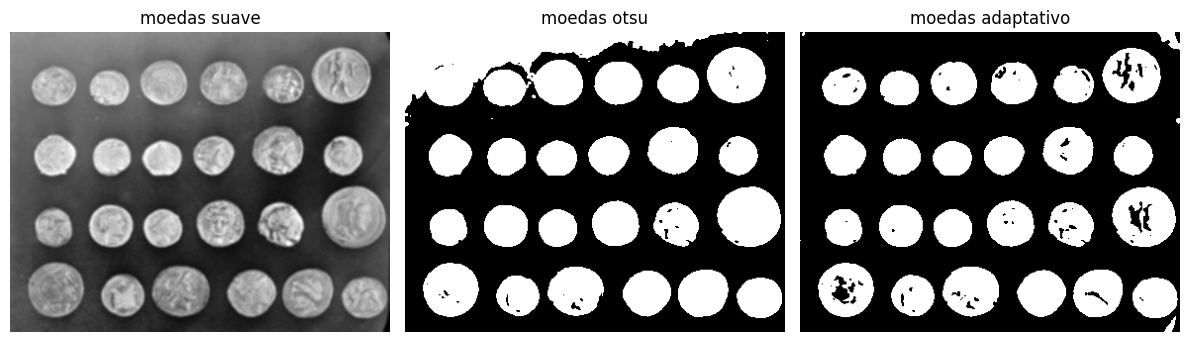

In [4]:
_, moedas_otsu = cv2.threshold(moedas_suave, 0, 255, cv2.THRESH_OTSU)

# Parâmetros reconstituídos porque o fim desta linha foi cortado no PDF.
# A escolha foi validada comparando o resultado e a contagem final de 24 contornos.
moedas_adapt = cv2.adaptiveThreshold(
    moedas_suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 101, -10
)

mostrar(
    [moedas_suave, moedas_otsu, moedas_adapt],
    ["moedas suave", "moedas otsu", "moedas adaptativo"]
)


## Detecção e filtragem dos contornos

In [5]:
contornos, _ = cv2.findContours(
    moedas_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

contornos = [c for c in contornos if cv2.contourArea(c) > 500]
print('Quantidade de contornos: ', len(contornos))


Quantidade de contornos:  24


## Desenho e numeração dos contornos

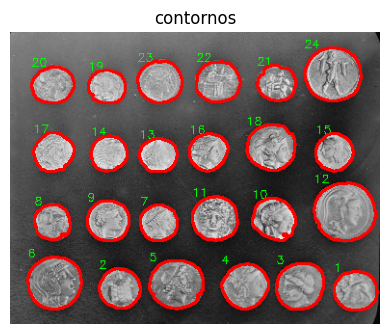

In [6]:
saida = cv2.cvtColor(moedas, cv2.COLOR_GRAY2BGR)

for i, c in enumerate(contornos):
    (x, y, w, h) = cv2.boundingRect(c)
    cv2.putText(saida, str(i + 1), (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0))

mostrar([cv2.drawContours(saida, contornos, -1, (255, 0, 0), 2)], ["contornos"])


## Resultado

Com os parâmetros reconstruídos, a sequência encontra **24 contornos** (área maior que 500 pixels²), conforme o resultado exibido na segunda página do PDF. As figuras acima foram geradas ao executar este notebook.